## EDA Univariate Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
df = pd.read_csv("Student Social Media And Mental Health Impact.csv")
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [3]:
df.shape

(5000, 13)

In [4]:
df.duplicated().sum()

np.int64(2)

In [5]:
df[df.duplicated()]

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
2405,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
2463,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5


In [6]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 507.9 KB


In [8]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,20.82180,1.736620,18.0,19.0,21.0,22.0,24.0
Avg_Daily_Usage_Hours,5000.0,5.07846,1.653913,1.0,3.8,5.0,6.3,8.8
Daily_Unlocks,5000.0,171.45260,42.858254,62.0,140.0,171.0,204.0,273.0
Study_Hours,5000.0,3.00842,1.637018,0.3,1.5,2.8,4.2,8.3
Physical_Activity_Hours,5000.0,1.75100,0.668398,-0.4,1.3,1.7,2.2,4.1
Sleep_Hours_Per_Night,5000.0,6.63458,1.221391,3.6,5.6,6.6,7.5,9.9
Mental_Health_Score,5000.0,6.23098,1.278701,3.6,5.1,6.1,7.1,9.4


In [9]:
display(df.describe(include="object").T)

,count,unique,top,freq
Gender,5000,2,Male,2635
Country,5000,111,Other,1880
Academic_Level,5000,3,Undergraduate,3632
Most_Used_Platform,5000,12,Instagram,1130
Purpose_Of_Use,5000,4,Entertainment,2552
Stress_Level,5000,4,Very High,1621


In [10]:
def analyze_numeric(col):
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    print(f"--- {col} ---")
    print(f"Mean={s.mean():.2f} | Median={s.median():.2f} | Mode={s.mode()[0]} | Std={s.std():.2f}")
    print(f"Min={s.min()} | Max={s.max()} | Skew={s.skew():.2f} | Kurtosis={s.kurt():.2f}")
    print(f"IQR outliers: {n_out} ({n_out/len(s)*100:.2f}%)")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(s, kde=True, ax=ax[0], color="steelblue")
    ax[0].axvline(s.mean(), color="red", ls="--", label="Mean")
    ax[0].axvline(s.median(), color="green", ls="--", label="Median")
    ax[0].legend(); ax[0].set_title(f"Distribution of {col}")
    sns.boxplot(x=s, ax=ax[1], color="lightcoral")
    ax[1].set_title(f"Boxplot of {col}")
    plt.tight_layout(); plt.show()

In [11]:
def analyze_categorical(col, top_n=None, horizontal=False):
    counts = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    print(f"--- {col} --- (unique = {df[col].nunique()})")
    display(pd.DataFrame({"Count": counts, "Percent": pct.round(2)}).head(top_n))
    data = counts.head(top_n)
    plt.figure(figsize=(10, 5))
    if horizontal:
        sns.barplot(x=data.values, y=data.index, palette="viridis")
    else:
        ax = sns.barplot(x=data.index, y=data.values, palette="viridis")
        plt.xticks(rotation=30)
    plt.title(f"Count of {col}"); plt.tight_layout(); plt.show()

## Age

--- Age ---
Mean=20.82 | Median=21.00 | Mode=21 | Std=1.74
Min=18 | Max=24 | Skew=0.16 | Kurtosis=-0.91
IQR outliers: 0 (0.00%)


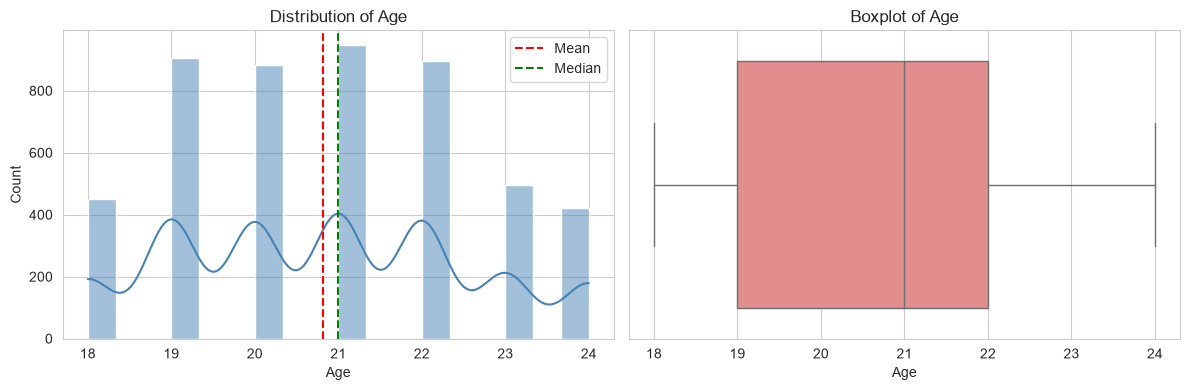

In [12]:
analyze_numeric("Age")

In [13]:
df["Age"].value_counts().sort_index()

Age
18    450
19    906
20    883
21    947
22    896
23    496
24    422
Name: count, dtype: int64

### Observations: Age

- Ages range from 18 to 24, with a mean of about 20.8 and a median of 21, so this is a young college-age sample.
- The distribution is nearly symmetric (skew about 0.16) with no outliers.
- Ages 19 to 22 hold the bulk of the data (about 900 students each). Ages 18 (450), 23 (496) and 24 (422) are about half as common.
- Age is a discrete variable with only 7 values, so a countplot suits it better than a smooth KDE.
- The narrow range means age will probably have limited predictive power, though the mix of high school and graduate levels suggests the labels may not line up neatly with age.

## Gender

--- Gender --- (unique = 2)


,Count,Percent
Gender,,
Male,2635,52.7
Female,2365,47.3


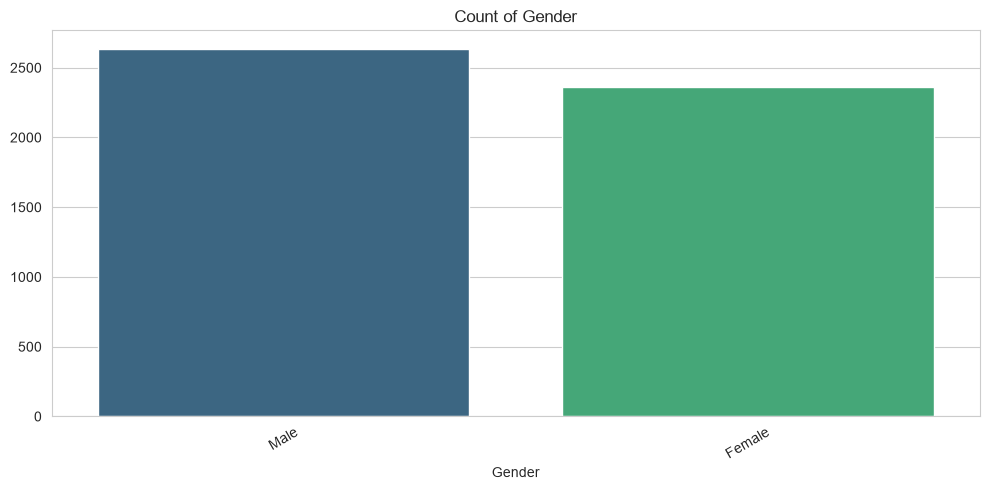

In [14]:
analyze_categorical("Gender")

### Observations: Gender

- There are two categories: Male (about 52.7%) and Female (about 47.3%).
- The split is nearly balanced, so there is no meaningful class imbalance and no gender-bias risk from sampling.
- No missing or inconsistent labels.

## Country

--- Country --- (unique = 111)


,Count,Percent
Country,,
Other,1880,37.60
India,389,7.78
USA,355,7.10
Canada,230,4.60
Australia,198,3.96
UK,185,3.70
Germany,136,2.72
Mexico,94,1.88
Turkey,94,1.88


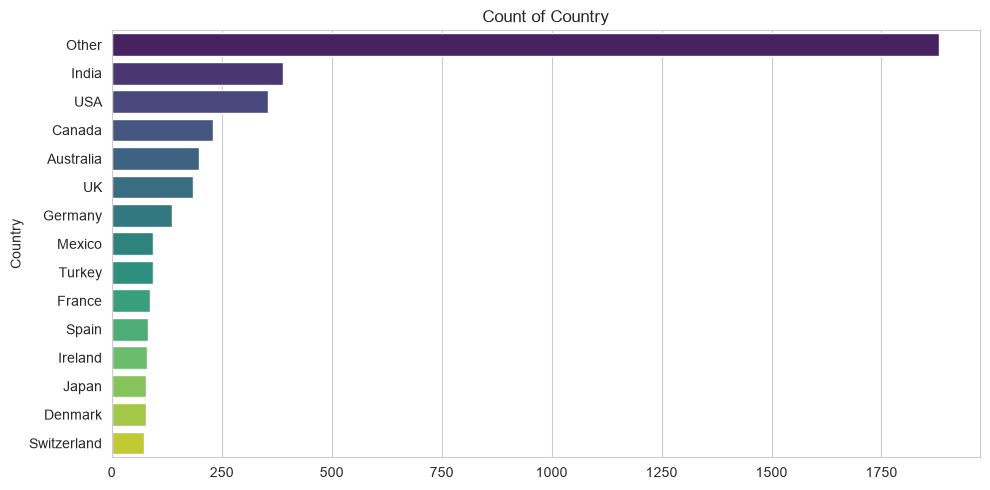

In [15]:
analyze_categorical("Country", top_n=15, horizontal=True)

### Observations: Country

- There are 111 unique values, making this a high-cardinality column.
- “Other” is the largest category at 1,880 rows (about 37.6%), so it is a catch-all bucket rather than a real country and hides a lot of detail.
- Among named countries, India (389, about 7.8%) and the USA (355, about 7.1%) lead. Canada (230), Australia (198), UK (185), Germany (136) and Mexico (94) follow.
- Distribution is heavily long-tailed: many countries have very few students.
- For modeling, group rare countries into “Other” or use frequency/target encoding rather than one-hot encoding.

## Academic_Level

--- Academic_Level --- (unique = 3)


,Count,Percent
Academic_Level,,
Undergraduate,3632,72.64
Graduate,918,18.36
High School,450,9.00


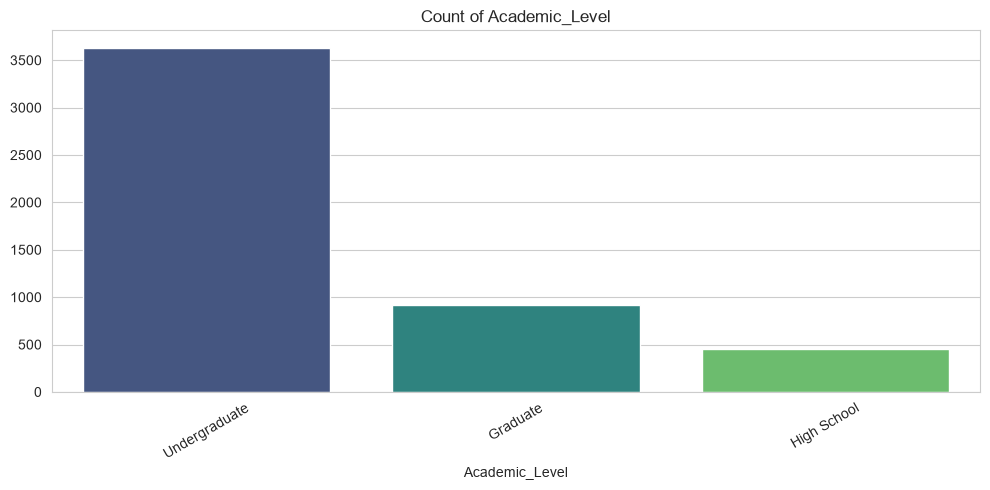

In [16]:
analyze_categorical("Academic_Level")

### Observations: Academic_Level

- Three categories: Undergraduate (about 72.6%), Graduate (about 18.4%) and High School (about 9.0%).
- The data is dominated by undergraduates, and high school students are a small minority, so any group-level conclusions for them are less reliable.
- The categories are ordinal (High School < Undergraduate < Graduate), so ordinal encoding is appropriate.

## Most_Used_Platform

--- Most_Used_Platform --- (unique = 12)


,Count,Percent
Most_Used_Platform,,
Instagram,1130,22.60
TikTok,918,18.36
Facebook,719,14.38
LinkedIn,523,10.46
YouTube,491,9.82
Twitter,462,9.24
Snapchat,420,8.40
WhatsApp,175,3.50
LINE,50,1.00


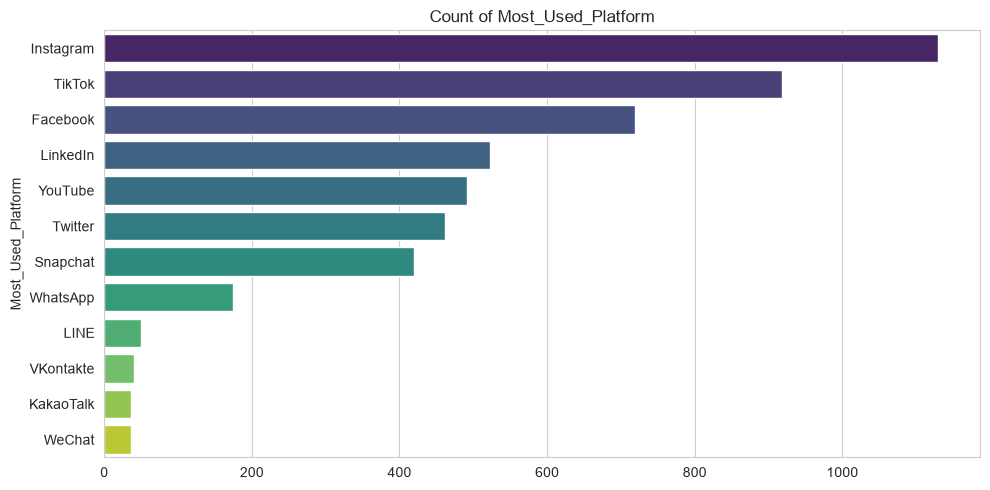

In [17]:
analyze_categorical("Most_Used_Platform", horizontal= True)

### Observations: Most_Used_Platform

- There are 12 platforms. Instagram leads (about 22.6%), then TikTok (18.4%) and Facebook (14.4%).
- LinkedIn (10.5%), YouTube (9.8%), Twitter (9.2%) and Snapchat (8.4%) form the middle tier.
- WhatsApp (3.5%), LINE (1.0%), VKontakte (0.8%), KakaoTalk (0.7%) and WeChat (0.7%) are very rare, with only about 35 to 50 rows each.
- Instagram, TikTok and Facebook together cover about 55% of students.
- The rare platforms are mostly region-specific apps and could be grouped as “Other” to avoid sparse categories in modeling.

## Purpose_Of_Use

--- Purpose_Of_Use --- (unique = 4)


,Count,Percent
Purpose_Of_Use,,
Entertainment,2552,51.04
Education,1094,21.88
Networking,793,15.86
News,561,11.22


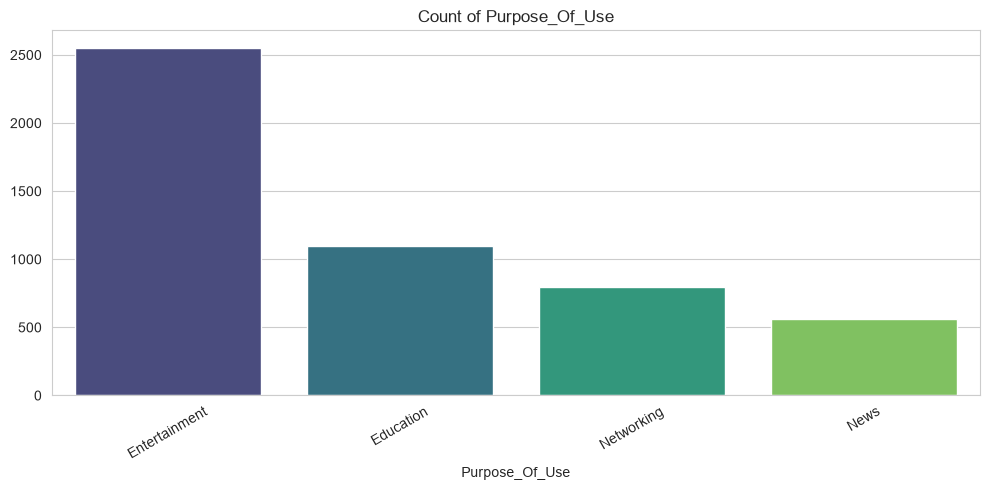

In [18]:
analyze_categorical("Purpose_Of_Use")

### Observations: Purpose_Of_Use

- Four categories: Entertainment (about 51%), Education (21.9%), Networking (15.9%) and News (11.2%).
- Entertainment alone accounts for about half of all usage, so most students use social media for leisure rather than academic or professional purposes.
- Only about 1 in 5 students mainly uses it for education.
- All categories have enough samples for reliable analysis.

## Avg_Daily_Usage_Hours

--- Avg_Daily_Usage_Hours ---
Mean=5.08 | Median=5.00 | Mode=4.7 | Std=1.65
Min=1.0 | Max=8.8 | Skew=0.01 | Kurtosis=-0.77
IQR outliers: 0 (0.00%)


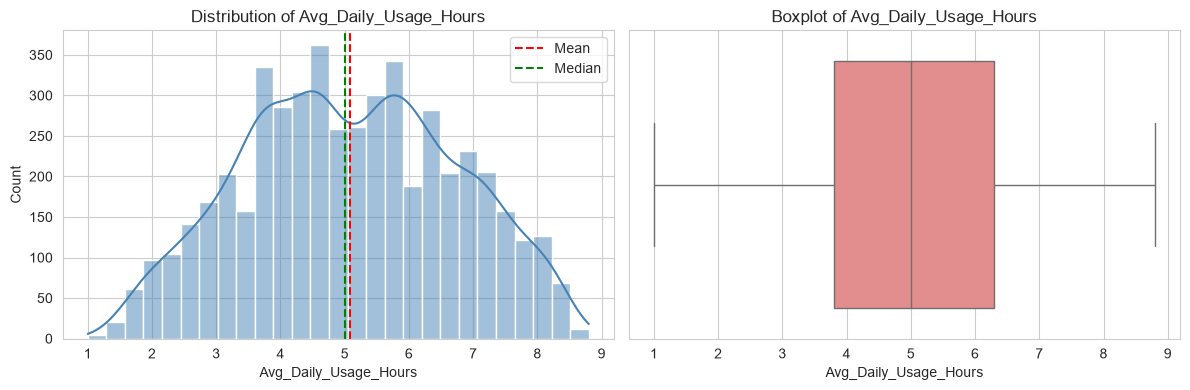

In [19]:
analyze_numeric("Avg_Daily_Usage_Hours")

### Observations: Avg_Daily_Usage_Hours

- Range is 1.0 to 8.8 hours, with a mean of about 5.08 and a median of 5.0.
- Mean and median almost coincide and skew is about 0.01, so the distribution is close to a symmetric, bell-shaped curve.
- The middle 50% of students use social media 3.8 to 6.3 hours a day.
- A typical student spends over 5 hours daily on social media, which is a high level of use.
- Outliers are minimal or absent, so no treatment is needed.

## Daily_Unlocks

--- Daily_Unlocks ---
Mean=171.45 | Median=171.00 | Mode=154 | Std=42.86
Min=62 | Max=273 | Skew=0.00 | Kurtosis=-0.71
IQR outliers: 0 (0.00%)


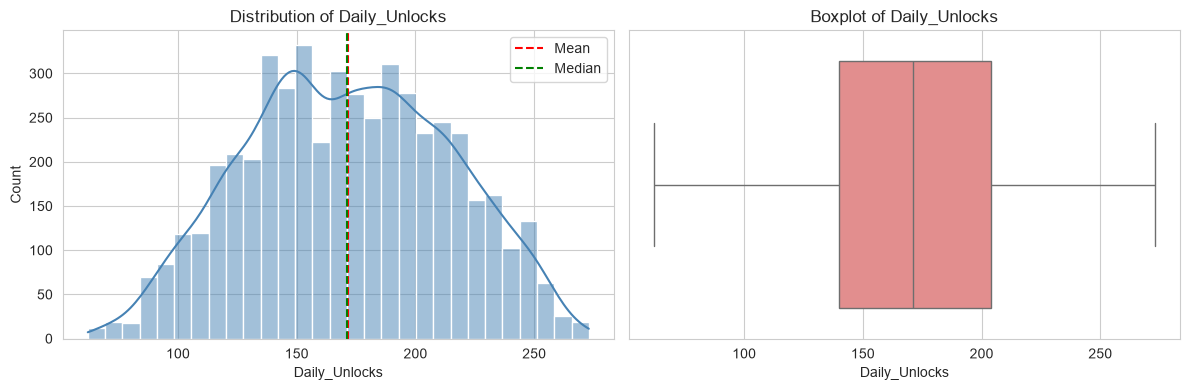

In [20]:
analyze_numeric("Daily_Unlocks")

### Observations: Daily_Unlocks

- Range is 62 to 273 unlocks per day, with a mean of about 171.5 and a median of 171.
- Skew is about 0, giving an almost perfectly symmetric, normal-like distribution.
- The middle 50% falls between 140 and 204, which is roughly one phone check every 5 to 6 waking minutes.
- Even the lowest value (62) is high, which suggests heavy habitual phone checking across the whole sample.
- No outliers.

## Study_Hours

--- Study_Hours ---
Mean=3.01 | Median=2.80 | Mode=1.0 | Std=1.64
Min=0.3 | Max=8.3 | Skew=0.44 | Kurtosis=-0.73
IQR outliers: 2 (0.04%)


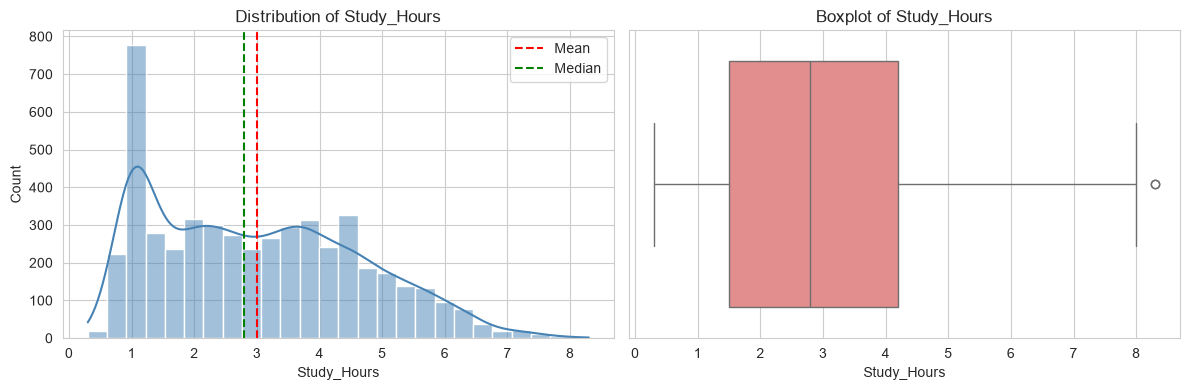

In [21]:
analyze_numeric("Study_Hours")

### Observations: Study_Hours

- Range is 0.3 to 8.3 hours, with a mean of about 3.0 and a median of 2.8.
- The mean is above the median and skew is about 0.44, so the distribution is moderately right-skewed. Most students study 1.5 to 4.2 hours, and a smaller group studies much longer.
- The boxplot may flag a few high-study-hour outliers, which are plausible values (such as exam periods or graduate students) rather than errors.
- Average study time (about 3 hours) is well below average social media time (about 5 hours).

## Physical_Activity_Hours

--- Physical_Activity_Hours ---
Mean=1.75 | Median=1.70 | Mode=1.6 | Std=0.67
Min=-0.4 | Max=4.1 | Skew=0.04 | Kurtosis=-0.23
IQR outliers: 22 (0.44%)


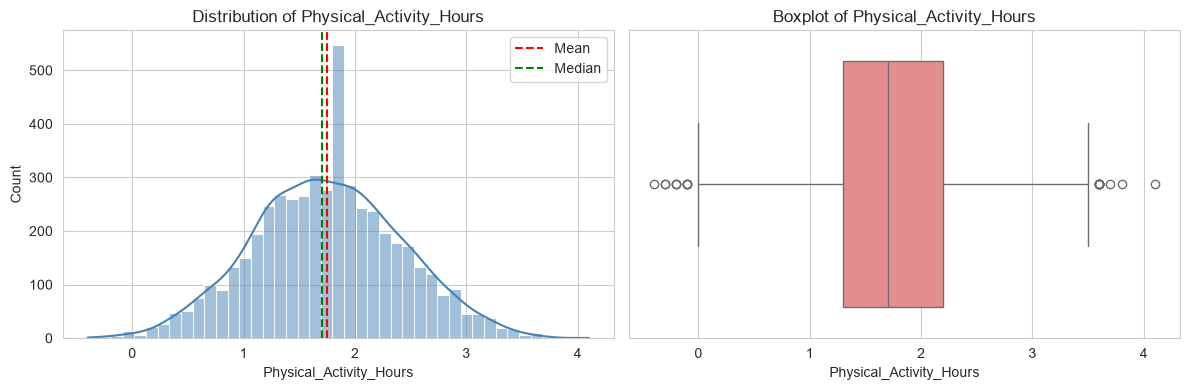

In [22]:
analyze_numeric("Physical_Activity_Hours")

In [23]:
print("Negative values:", (df["Physical_Activity_Hours"] < 0).sum())

Negative values: 10


### Observations: Physical_Activity_Hours

- Mean is about 1.75 hours and median is about 1.7, with skew near 0.04, so the distribution is nearly symmetric.
- The minimum is -0.4, which is impossible for hours of activity. This is a data quality issue, so check how many negative rows exist (printed above).
- Fix this by clipping at 0, replacing the values with the median, or dropping those rows, and document the choice.
- The typical range is 1.3 to 2.2 hours per day, with a maximum of 4.1.
- Most students are moderately active, and very few exercise more than 3 hours.

## Sleep_Hours_Per_Night

--- Sleep_Hours_Per_Night ---
Mean=6.63 | Median=6.60 | Mode=7.2 | Std=1.22
Min=3.6 | Max=9.9 | Skew=0.12 | Kurtosis=-0.88
IQR outliers: 0 (0.00%)


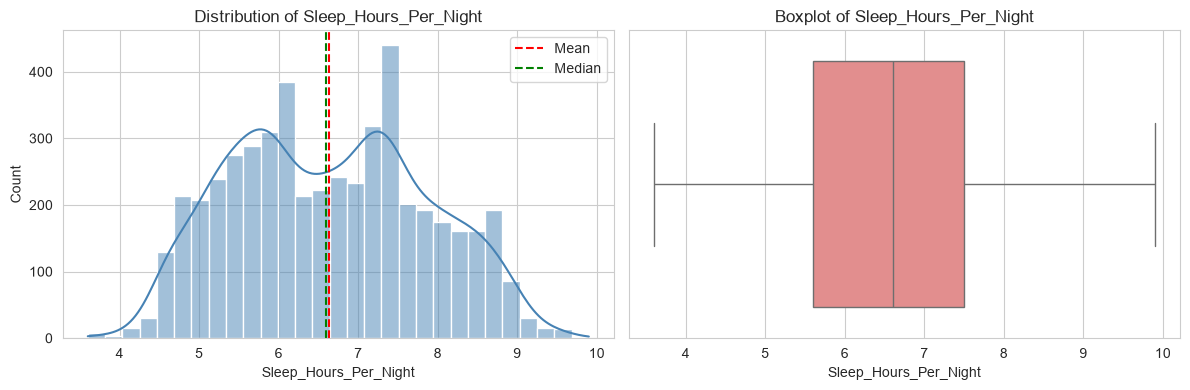

In [24]:
analyze_numeric("Sleep_Hours_Per_Night")

### Observations: Sleep_Hours_Per_Night

- Range is 3.6 to 9.9 hours, with a mean of about 6.63 and a median of 6.6.
- Skew is about 0.12, so the distribution is nearly symmetric.
- The mean is below the commonly recommended 7 to 9 hours for young adults, and the 25th percentile (5.6 hours) shows that a sizable group is sleep deprived.
- About 25% of students sleep 7.5 hours or more, so the healthy sleepers are a minority tail.
- Values below 4 hours are extreme but plausible.

## Stress_Level

--- Stress_Level --- (unique = 4)


,Count,Percent
Stress_Level,,
Very High,1621,32.42
High,1440,28.80
Medium,1295,25.90
Low,644,12.88


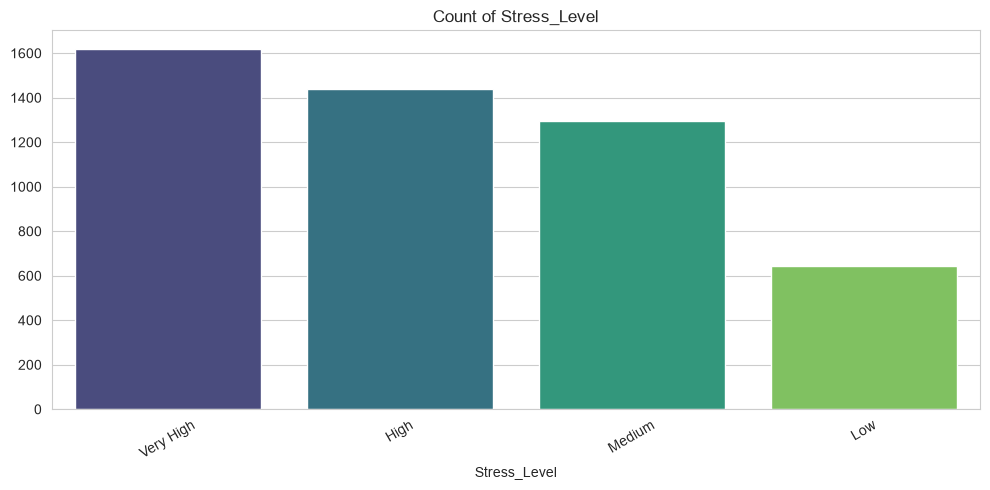

In [25]:
analyze_categorical("Stress_Level")

### Observations: Stress_Level

- Four ordinal categories: Very High (about 32.4%), High (28.8%), Medium (25.9%) and Low (12.9%).
- About 61% of students report High or Very High stress, and only about 13% report Low stress, so this sample is heavily stress-affected.
- The distribution is skewed toward the high end, and “Very High” is the single most common category.
- Use ordinal encoding (Low=0 to Very High=3) in modeling.

## Mental_Health_Score

--- Mental_Health_Score ---
Mean=6.23 | Median=6.10 | Mode=6.0 | Std=1.28
Min=3.6 | Max=9.4 | Skew=0.21 | Kurtosis=-0.80
IQR outliers: 0 (0.00%)


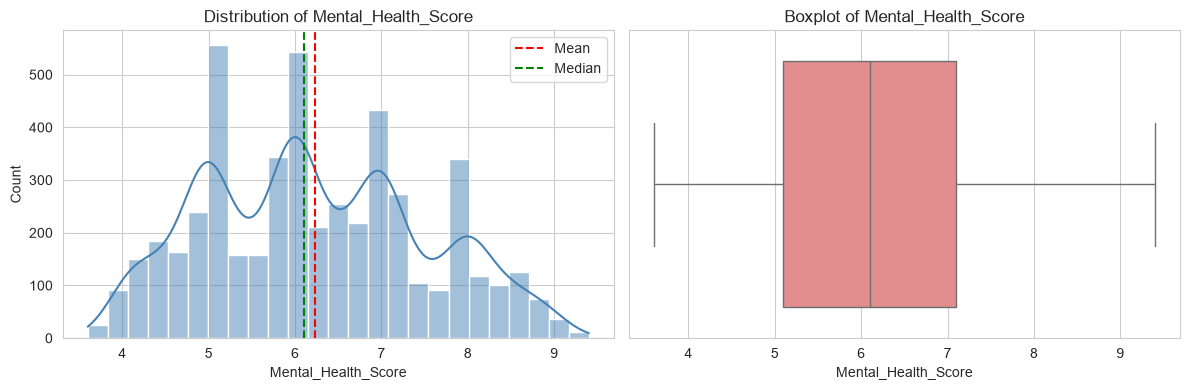

In [26]:
analyze_numeric("Mental_Health_Score")

### Observations: Mental_Health_Score

- Range is 3.6 to 9.4, with a mean of about 6.23 and a median of 6.1.
- Skew is about 0.21, a slight right skew, so a small group of students has noticeably higher (better) scores.
- The middle 50% fall between 5.1 and 7.1, so most students sit in the lower-middle to middle range.
- The scale seems to be about 1 to 10, with a higher score meaning better mental health. This is an assumption, so confirm it against the dataset documentation.
- It is a likely target variable for later bivariate analysis against usage, sleep and stress.

In [27]:
#1. To drop duplicates
df = df.drop_duplicates()

#2. Converting negative or unrealitstic value to realistic value
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

## Feature Engineering

In [28]:
top_countries = df['Country'].value_counts().index[:10].tolist()

In [29]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [30]:
df['Grouped_country'] = df['Country'].apply(group_countries)

In [31]:
df['Grouped_country'].value_counts()

Grouped_country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

In [32]:
skwewd_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Grouped_country"]

In [33]:
feature_col = skwewd_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
#1. Skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())

])

#2. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

#3. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

#4. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])

In [36]:
preprocessor = ColumnTransformer(transformers=[
    ("Skewed_Pipeline", skew_pipeline, skwewd_col),
    ("Plain_Numeric",plain_numeric_pipeline, other_numeric_cols ),
    ('Ordinal', ordinal_pipeline, ordinal_col),
    ('Normal', nominal_pipeline, normal_col)
])

## Baseline Model

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_preds       = lr_pipeline.predict(X_test)
lr_preds_train = lr_pipeline.predict(X_train)

lr_r2_testing  = r2_score(y_test, lr_preds)
lr_r2_training = r2_score(y_train, lr_preds_train)
lr_mae         = mean_absolute_error(y_test, lr_preds)
lr_rmse        = root_mean_squared_error(y_test, lr_preds)

print(f"Accuracy of Training {lr_r2_training}")
print(f"Accuracy of Testing {lr_r2_testing}")
print(f'MAE {lr_mae}')
print(f'RMSE {lr_rmse}')

Accuracy of Training 0.7236771199387539
Accuracy of Testing 0.7397944617433021
MAE 0.5361775634720182
RMSE 0.6760318429888342


## Xgboost Regressor

In [38]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('xgboost', XGBRegressor(random_state=42))
])

xgb_pipeline.fit(X_train, y_train)
xgb_preds          = xgb_pipeline.predict(X_test)
xgb_preds_training = xgb_pipeline.predict(X_train)

xgb_r2_testing  = r2_score(y_test, xgb_preds)
xgb_r2_training = r2_score(y_train, xgb_preds_training)
xgb_mae         = mean_absolute_error(y_test, xgb_preds)
xgb_rmse        = root_mean_squared_error(y_test, xgb_preds)

print(f"Accuracy of Training {xgb_r2_training}")
print(f"Accuracy of Testing {xgb_r2_testing}")
print(f"MAE : {xgb_mae}")
print(f"RMSE : {xgb_rmse}")

Accuracy of Training 0.9751720148923269
Accuracy of Testing 0.877165603954614
MAE : 0.3519394182523091
RMSE : 0.4644819934262295


## Gradient Boosting Regressor

In [39]:
from sklearn.ensemble import GradientBoostingRegressor

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('gradient boosting', GradientBoostingRegressor(random_state=42))
])

gb_pipeline.fit(X_train, y_train)
gb_preds          = gb_pipeline.predict(X_test)
gb_preds_training = gb_pipeline.predict(X_train)

gb_r2_testing  = r2_score(y_test, gb_preds)
gb_r2_training = r2_score(y_train, gb_preds_training)
gb_mae         = mean_absolute_error(y_test, gb_preds)
gb_rmse        = root_mean_squared_error(y_test, gb_preds)

print(f"Accuracy of Training {gb_r2_training}")
print(f"Accuracy of Testing {gb_r2_testing}")
print(f"MAE : {gb_mae}")
print(f"RMSE : {gb_rmse}")

Accuracy of Training 0.8129435097191944
Accuracy of Testing 0.7990623492431768
MAE : 0.46540191468389236
RMSE : 0.5940726314540831


## Random Forest Regressor

In [40]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('random forest', RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_preds          = rf_pipeline.predict(X_test)
rf_preds_training = rf_pipeline.predict(X_train)

rf_r2_testing  = r2_score(y_test, rf_preds)
rf_r2_training = r2_score(y_train, rf_preds_training)
rf_mae         = mean_absolute_error(y_test, rf_preds)
rf_rmse        = root_mean_squared_error(y_test, rf_preds)

print(f"Accuracy of Training {rf_r2_training}")
print(f"Accuracy of Testing {rf_r2_testing}")
print(f"MAE : {rf_mae}")
print(f"RMSE : {rf_rmse}")

Accuracy of Training 0.9809069341581819
Accuracy of Testing 0.8780167461546369
MAE : 0.34650236666666673
RMSE : 0.46286995531682545


## Support Vector Regressor

In [41]:
from sklearn.svm import SVR

svr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('svr', SVR())
])

svr_pipeline.fit(X_train, y_train)
svr_preds          = svr_pipeline.predict(X_test)
svr_preds_training = svr_pipeline.predict(X_train)

svr_r2_testing  = r2_score(y_test, svr_preds)
svr_r2_training = r2_score(y_train, svr_preds_training)
svr_mae         = mean_absolute_error(y_test, svr_preds)
svr_rmse        = root_mean_squared_error(y_test, svr_preds)

print(f"Accuracy of Training {svr_r2_training}")
print(f"Accuracy of Testing {svr_r2_testing}")
print(f"MAE : {svr_mae}")
print(f"RMSE : {svr_rmse}")

Accuracy of Training 0.8264123842614473
Accuracy of Testing 0.8071738284948615
MAE : 0.4361028056968646
RMSE : 0.5819583102867559


## Decision Tree Regressor

In [42]:
from sklearn.tree import DecisionTreeRegressor

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('decision tree', DecisionTreeRegressor(random_state=42))
])

dt_pipeline.fit(X_train, y_train)
dt_preds          = dt_pipeline.predict(X_test)
dt_preds_training = dt_pipeline.predict(X_train)

dt_r2_testing  = r2_score(y_test, dt_preds)
dt_r2_training = r2_score(y_train, dt_preds_training)
dt_mae         = mean_absolute_error(y_test, dt_preds)
dt_rmse        = root_mean_squared_error(y_test, dt_preds)

print(f"Accuracy of Training {dt_r2_training}")
print(f"Accuracy of Testing {dt_r2_testing}")
print(f"MAE : {dt_mae}")
print(f"RMSE : {dt_rmse}")

Accuracy of Training 0.9999918615442751
Accuracy of Testing 0.7469753717862024
MAE : 0.4247333333333333
RMSE : 0.6666383327312244


In [43]:
# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Xgboost Regressor', 'Gradient Boosting Regressor', 'Random Forest Regressor', 'Support Vector Regressor', 'Decision Tree Regressor'],
    'Testing R2': [lr_r2_testing, xgb_r2_testing, gb_r2_testing, rf_r2_testing, svr_r2_testing, dt_r2_testing],
    'Training R2': [lr_r2_training, xgb_r2_training, gb_r2_training, rf_r2_training, svr_r2_training, dt_r2_training],
    'MAE': [lr_mae, xgb_mae, gb_mae, rf_mae, svr_mae, dt_mae],
    'RMSE': [lr_rmse, xgb_rmse, gb_rmse, rf_rmse, svr_rmse, dt_rmse]
})
results['Overfit Gap'] = results['Training R2'] - results['Testing R2']
results = results.sort_values(by='Testing R2', ascending=False).reset_index(drop=True)
results

,Model,Testing R2,Training R2,MAE,RMSE,Overfit Gap
0,Random Forest Regressor,0.878017,0.980907,0.346502,0.462870,0.102890
1,Xgboost Regressor,0.877166,0.975172,0.351939,0.464482,0.098006
2,Support Vector Regressor,0.807174,0.826412,0.436103,0.581958,0.019239
3,Gradient Boosting Regressor,0.799062,0.812944,0.465402,0.594073,0.013881
4,Decision Tree Regressor,0.746975,0.999992,0.424733,0.666638,0.253016
5,Linear Regression,0.739794,0.723677,0.536178,0.676032,-0.016117


## Hyperparameter Tuning

In [44]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'random forest__n_estimators':      [200, 300, 500],
    'random forest__max_depth':         [8, 12, 16, 20, None],
    'random forest__min_samples_split': [2, 5, 10],
    'random forest__min_samples_leaf':  [1, 2, 4, 8],
    'random forest__max_features':      ['sqrt', 0.5, 0.7, 1.0],
    'random forest__bootstrap':         [True],
    'random forest__max_samples':       [0.7, 0.8, 0.9, None],
}

rf_search = RandomizedSearchCV(
    rf_pipeline, param_dist, n_iter=30, cv=5,
    scoring='r2', random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'random forest__bootstrap': [True], 'random forest__max_depth': [8, 12, ...], 'random forest__max_features': ['sqrt', 0.5, ...], 'random forest__max_samples': [0.7, 0.8, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly o

In [45]:
rf_search.best_params_

{'random forest__n_estimators': 300,
 'random forest__min_samples_split': 2,
 'random forest__min_samples_leaf': 1,
 'random forest__max_samples': 0.9,
 'random forest__max_features': 'sqrt',
 'random forest__max_depth': None,
 'random forest__bootstrap': True}

In [46]:
rf_best_pipeline = rf_search.best_estimator_
rf_best_preds    = rf_best_pipeline.predict(X_test)

print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print(f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")

R2 Score for random forest after hyperparameter tuning 0.8897408952699835
MAE Score for random forest after hyperparameter tuning 0.3307026111111106


In [47]:
rf_tuned_preds          = rf_best_pipeline.predict(X_test)
rf_tuned_training       = rf_best_pipeline.predict(X_train)

rf_tuned_r2_testing  = r2_score(y_test, rf_tuned_preds)
rf_tuned_r2_training = r2_score(y_train, rf_tuned_training)
rf_tuned_mae         = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_rmse        = root_mean_squared_error(y_test, rf_tuned_preds)

print(f"Accuracy of Training {rf_tuned_r2_training}")
print(f"Accuracy of Testing {rf_tuned_r2_testing}")
print(f"MAE : {rf_tuned_mae}")
print(f"RMSE : {rf_tuned_rmse}")

Accuracy of Training 0.9799409073078519
Accuracy of Testing 0.8897408952699835
MAE : 0.3307026111111106
RMSE : 0.44006427749755417


In [48]:
results = pd.DataFrame({
    'Model': ['Xgboost Regressor', 'Random Forest Regressor (default)', 'Random Forest Regressor (tuned)'],
    'Testing R2': [xgb_r2_testing, rf_r2_testing, rf_tuned_r2_testing],
    'Training R2': [xgb_r2_training, rf_r2_training, rf_tuned_r2_training],
    'MAE': [xgb_mae, rf_mae, rf_tuned_mae],
    'RMSE': [xgb_rmse, rf_rmse, rf_tuned_rmse]
})
results['Overfit Gap'] = results['Training R2'] - results['Testing R2']
results = results.sort_values(by='Testing R2', ascending=False).reset_index(drop=True)
results

,Model,Testing R2,Training R2,MAE,RMSE,Overfit Gap
0,Random Forest Regressor (tuned),0.889741,0.979941,0.330703,0.440064,0.090200
1,Random Forest Regressor (default),0.878017,0.980907,0.346502,0.462870,0.102890
2,Xgboost Regressor,0.877166,0.975172,0.351939,0.464482,0.098006


In [49]:
import joblib
joblib.dump(rf_best_pipeline, 'mental_health_model.pkl')

['mental_health_model.pkl']